# Sentinel-1 ship detection: Istanbul case study (v2.1)

Pipeline: Sentinel-1 RTC download → dB → 3 × 3 median filter → CA-CFAR detector with guard cells → clustering → land masking → AIS placeholder (random labels).

v2.1 change: the detector now excludes a 5 × 5 guard window around the pixel under test when estimating the background (v2.0 used the plain mean of the whole 15 × 15 window).

Known limitations (see README.md): the image is resampled to 1000 × 1000 px, the land mask uses coarse Natural Earth polygons, and the AIS step uses random labels instead of real AIS data.


In [1]:
!pip install pystac-client planetary-computer rasterio geopandas shapely affine

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 26/26 [planetary-computer]


--- 1. SEARCHING THE SENTINEL-1 RTC CATALOGUE ---
Scene: S1A_IW_GRDH_1SDV_20230811T160002_20230811T160027_049830_05FE26_rtc

--- 2. READING VV / VH AND CONVERTING TO dB ---
Done.



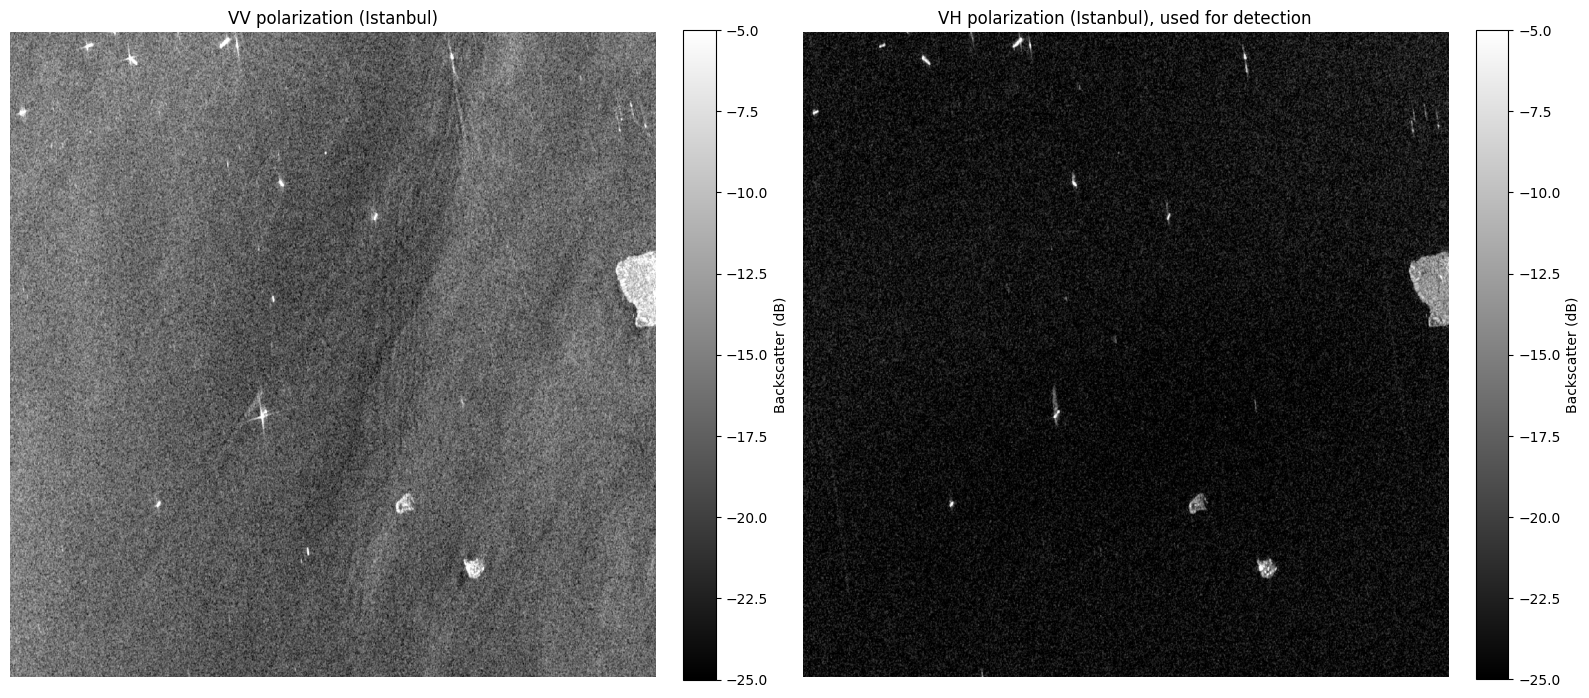

In [2]:
# --- STAGE 1: DATA (Sentinel-1 RTC from Microsoft Planetary Computer) ---
import pystac_client
import planetary_computer
import rasterio
from rasterio.warp import transform_bounds
from rasterio.windows import from_bounds
import numpy as np
import matplotlib.pyplot as plt

print("--- 1. SEARCHING THE SENTINEL-1 RTC CATALOGUE ---")
katalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace,
)

# Area of interest: Istanbul Ahirkapi anchorage
bbox_istanbul = [28.85, 40.85, 29.05, 40.95]
tarih_araligi = "2023-08-01/2023-08-15"
# The scene is pinned so that results stay reproducible even if the catalogue order changes
SAHNE_ID = "S1A_IW_GRDH_1SDV_20230811T160002_20230811T160027_049830_05FE26_rtc"

arama = katalog.search(
    collections=["sentinel-1-rtc"],
    bbox=bbox_istanbul,
    datetime=tarih_araligi,
)

secilen_radar = next(item for item in arama.items() if item.id == SAHNE_ID)
print(f"Scene: {secilen_radar.id}")

def radar_oku_ve_db_cevir(url, bbox, sekil=(1000, 1000)):
    # Note: out_shape resamples the window to 1000 x 1000 px (about 17 m x 11 m pixels here).
    # This is a known limitation; the native resolution is 10 m.
    with rasterio.open(url) as src:
        utm_bbox = transform_bounds('EPSG:4326', src.crs, *bbox)
        pencere = from_bounds(*utm_bbox, src.transform)

        ham_sinyal = src.read(1, window=pencere, out_shape=sekil).astype(np.float32)
        ham_sinyal = np.nan_to_num(ham_sinyal, nan=1e-6)
        ham_sinyal[ham_sinyal <= 0] = 1e-6
        db_matrisi = 10 * np.log10(ham_sinyal)
    return db_matrisi, pencere, src.transform, src.crs

print("\n--- 2. READING VV / VH AND CONVERTING TO dB ---")
vv_url = secilen_radar.assets["vv"].href
vv_db, pencere, src_transform, src_crs = radar_oku_ve_db_cevir(vv_url, bbox_istanbul)

vh_url = secilen_radar.assets["vh"].href
vh_db, _, _, _ = radar_oku_ve_db_cevir(vh_url, bbox_istanbul)

print("Done.\n")

# --- 3. DISPLAY ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))
vmin_db, vmax_db = -25, -5  # display range in dB

im1 = ax1.imshow(vv_db, cmap='gray', vmin=vmin_db, vmax=vmax_db)
ax1.set_title("VV polarization (Istanbul)")
ax1.axis('off')
fig.colorbar(im1, ax=ax1, fraction=0.046, pad=0.04, label="Backscatter (dB)")

im2 = ax2.imshow(vh_db, cmap='gray', vmin=vmin_db, vmax=vmax_db)
ax2.set_title("VH polarization (Istanbul), used for detection")
ax2.axis('off')
fig.colorbar(im2, ax=ax2, fraction=0.046, pad=0.04, label="Backscatter (dB)")

plt.tight_layout()
plt.show()


--- 3 x 3 MEDIAN FILTER ON THE VH CHANNEL ---
Done.



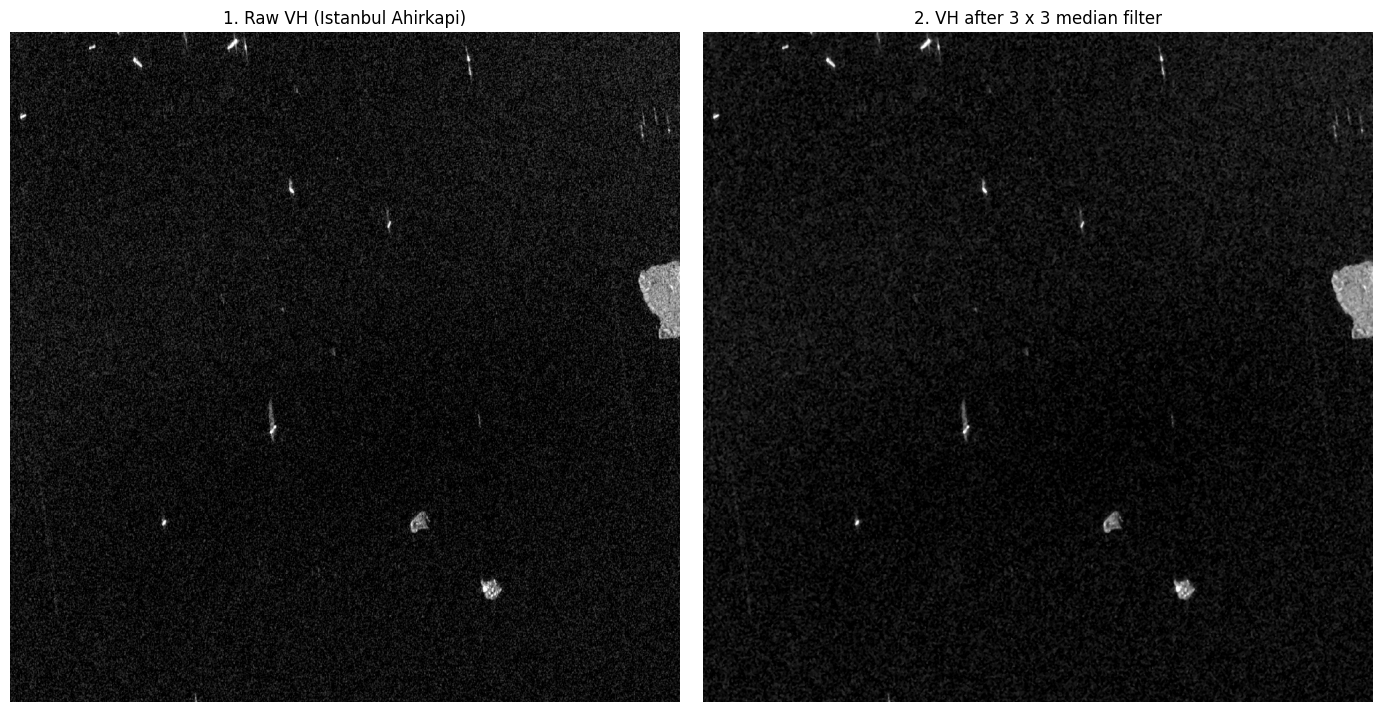

In [3]:
# --- STAGE 2: SPECKLE FILTERING ---
import scipy.ndimage as ndimage
import matplotlib.pyplot as plt

print("--- 3 x 3 MEDIAN FILTER ON THE VH CHANNEL ---")
vh_temiz = ndimage.median_filter(vh_db, size=3)
print("Done.\n")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7))
vmin_db, vmax_db = -25, -5

ax1.imshow(vh_db, cmap='gray', vmin=vmin_db, vmax=vmax_db)
ax1.set_title("1. Raw VH (Istanbul Ahirkapi)")
ax1.axis('off')

ax2.imshow(vh_temiz, cmap='gray', vmin=vmin_db, vmax=vmax_db)
ax2.set_title("2. VH after 3 x 3 median filter")
ax2.axis('off')

plt.tight_layout()
plt.show()


--- RUNNING THE DETECTOR ON THE FILTERED VH IMAGE ---
Done.



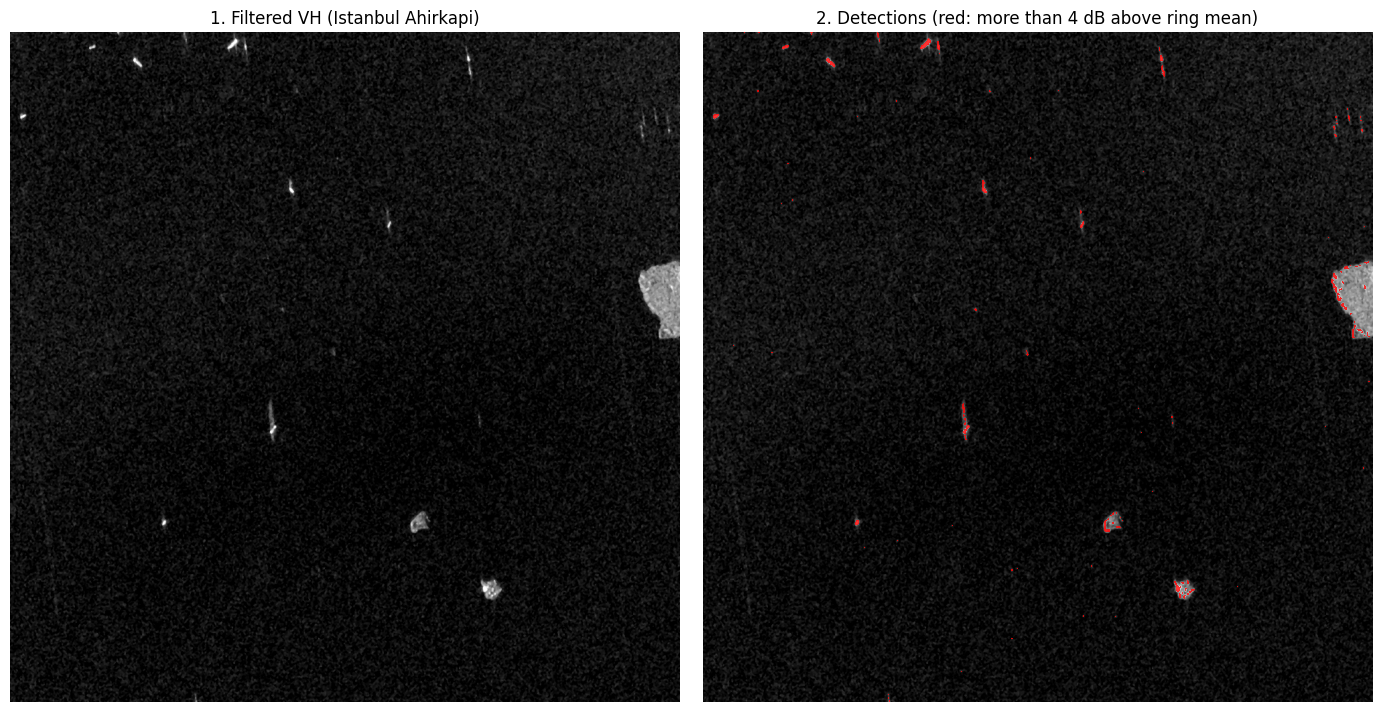

In [4]:
# --- STAGE 3: DETECTION (2D CA-CFAR WITH GUARD CELLS, v2.1) ---
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import uniform_filter

def cfar_2d(image, guard_size=2, bg_size=5, threshold_factor=4.0):
    """
    2D cell-averaging CFAR detector with guard cells, for SAR images in dB.
    The background is the mean of a hollow ring: the outer window of
    2 * (guard_size + bg_size) + 1 = 15 px minus the inner guard window of
    2 * guard_size + 1 = 5 px around the pixel under test (225 - 25 = 200 ring pixels).
    threshold_factor: offset in dB added to the background mean (not a multiplier).
    """
    outer = 2 * (guard_size + bg_size) + 1
    inner = 2 * guard_size + 1
    n_ring = outer ** 2 - inner ** 2

    # Sum of the outer window minus sum of the guard window = sum of the ring
    sum_outer = uniform_filter(image, size=outer) * outer ** 2
    sum_inner = uniform_filter(image, size=inner) * inner ** 2
    bg_mean = (sum_outer - sum_inner) / n_ring

    # A pixel is a detection if it is more than threshold_factor dB above the ring mean
    detection_mask = image > (bg_mean + threshold_factor)
    return detection_mask

print("--- RUNNING THE DETECTOR ON THE FILTERED VH IMAGE ---")
detection_mask = cfar_2d(vh_temiz, guard_size=2, bg_size=5, threshold_factor=4.0)
print("Done.\n")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7))
vmin_db, vmax_db = -25, -5

ax1.imshow(vh_temiz, cmap='gray', vmin=vmin_db, vmax=vmax_db)
ax1.set_title("1. Filtered VH (Istanbul Ahirkapi)")
ax1.axis('off')

ax2.imshow(vh_temiz, cmap='gray', vmin=vmin_db, vmax=vmax_db)
colored_mask = np.ma.masked_where(detection_mask == 0, detection_mask)
ax2.imshow(colored_mask, cmap='autumn', interpolation='none', alpha=0.8)
ax2.set_title("2. Detections (red: more than 4 dB above ring mean)")
ax2.axis('off')

plt.tight_layout()
plt.show()


In [5]:
# --- LAND MASKING HELPERS ---
import geopandas as gpd
from shapely.geometry import Point
from rasterio.transform import xy as transform_xy
from rasterio.windows import transform as window_transform
from affine import Affine
from shapely.geometry import box
from rasterio.warp import transform as coord_transform

def kara_verisini_yukle():
    """Load Natural Earth 10 m land polygons, clipped to a fixed box.
    Note: the clip box covers the Ahirkapi and Bosphorus test areas only. If you move the bbox
    outside it, no land is loaded and the land mask silently removes nothing."""
    url = "https://naciscdn.org/naturalearth/10m/physical/ne_10m_land.zip"
    kara_gdf = gpd.read_file(url)
    print(f"Land polygons CRS: {kara_gdf.crs}")
    bu_kutu = box(28.85, 40.90, 29.15, 41.10)
    kara_gdf = gpd.clip(kara_gdf, bu_kutu)
    return kara_gdf

def olceklenmis_transform_hesapla(orijinal_pencere, orijinal_src_transform, hedef_sekil):
    """
    Pixel -> map transform of the resampled array.
    orijinal_pencere: rasterio window (from from_bounds)
    orijinal_src_transform: src.transform of the file
    hedef_sekil: output shape used in out_shape, e.g. (1000, 1000)
    """
    pencere_transformu = window_transform(orijinal_pencere, orijinal_src_transform)
    x_oran = orijinal_pencere.width / hedef_sekil[1]
    y_oran = orijinal_pencere.height / hedef_sekil[0]
    return pencere_transformu * Affine.scale(x_oran, y_oran)

def kutu_merkezini_koordinata_cevir(kutu, olceklenmis_transform, kaynak_crs):
    """Bounding-box centre (pixel) -> longitude / latitude (WGS84)."""
    satir_merkezi = (kutu[0].start + kutu[0].stop) / 2
    sutun_merkezi = (kutu[1].start + kutu[1].stop) / 2
    utm_x, utm_y = transform_xy(olceklenmis_transform, satir_merkezi, sutun_merkezi)
    boylam_listesi, enlem_listesi = coord_transform(kaynak_crs, 'EPSG:4326', [utm_x], [utm_y])
    return boylam_listesi[0], enlem_listesi[0]

def karada_mi(boylam, enlem, kara_gdf):
    """True if the point falls inside a land polygon."""
    return kara_gdf.contains(Point(boylam, enlem)).any()

def land_mask_uygula(valid_vessels, olceklenmis_transform, kara_gdf, src_crs):
    """Keep only detections whose bounding-box centre is not on land."""
    deniz_ustundeki_hedefler = []
    for kutu in valid_vessels:
        boylam, enlem = kutu_merkezini_koordinata_cevir(kutu, olceklenmis_transform, src_crs)
        if not karada_mi(boylam, enlem, kara_gdf):
            deniz_ustundeki_hedefler.append(kutu)
    return deniz_ustundeki_hedefler


--- 1. GROUPING CONNECTED DETECTION PIXELS ---
--- 2. SIZE FILTER AND LAND MASKING ---
Land polygons CRS: EPSG:4326
Before land masking: 119 detections
After land masking:  119 detections
Removed as land:     0
These are detection candidates, not confirmed vessels (no ground truth for this scene).



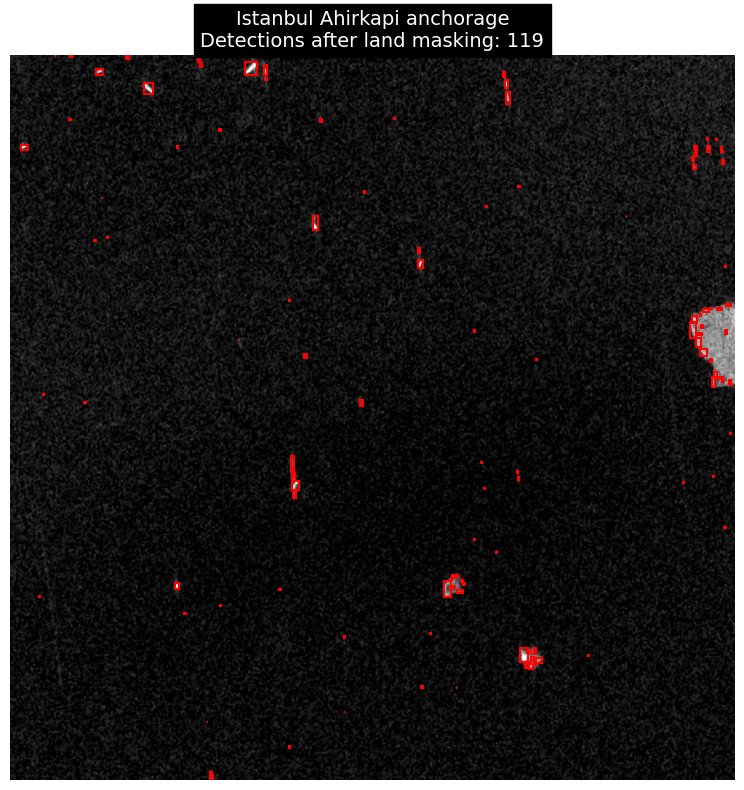

In [6]:
# --- STAGE 4: CLUSTERING AND LAND MASKING ---
import matplotlib.patches as patches
from scipy.ndimage import label, find_objects

print("--- 1. GROUPING CONNECTED DETECTION PIXELS ---")
connected_objects, num_objects = label(detection_mask)
box_coordinates = find_objects(connected_objects)

print("--- 2. SIZE FILTER AND LAND MASKING ---")
sekil = (1000, 1000)
valid_vessels = []
kara_gdf = kara_verisini_yukle()
olceklenmis_transform = olceklenmis_transform_hesapla(pencere, src_transform, sekil)

for kutu in box_coordinates:
    y_length = kutu[0].stop - kutu[0].start
    x_length = kutu[1].stop - kutu[1].start
    if y_length * x_length >= 2:
        valid_vessels.append(kutu)

karadan_once = len(valid_vessels)
valid_vessels = land_mask_uygula(valid_vessels, olceklenmis_transform, kara_gdf, src_crs)
karadan_sonra = len(valid_vessels)

print(f"Before land masking: {karadan_once} detections")
print(f"After land masking:  {karadan_sonra} detections")
print(f"Removed as land:     {karadan_once - karadan_sonra}")
print("These are detection candidates, not confirmed vessels (no ground truth for this scene).\n")

fig, ax = plt.subplots(1, 1, figsize=(12, 8))
ax.imshow(vh_temiz, cmap='gray', vmin=-25, vmax=-5)

for kutu in valid_vessels:
    y_start = kutu[0].start
    x_start = kutu[1].start
    height = kutu[0].stop - kutu[0].start
    width = kutu[1].stop - kutu[1].start
    rect = patches.Rectangle((x_start, y_start), width, height,
                             linewidth=1.5, edgecolor='red', facecolor='none')
    ax.add_patch(rect)

ax.set_title(f"Istanbul Ahirkapi anchorage\nDetections after land masking: {len(valid_vessels)}",
             color='white', backgroundcolor='black', fontsize=14)
ax.axis('off')

plt.tight_layout()
plt.show()


--- AIS PLACEHOLDER ---
No AIS data is used. Each detection gets a random label (80% 'AIS match', 20% 'no AIS').

Detections:                119
Random label 'AIS match':  95
Random label 'no AIS':     24
These labels are random and carry no information.



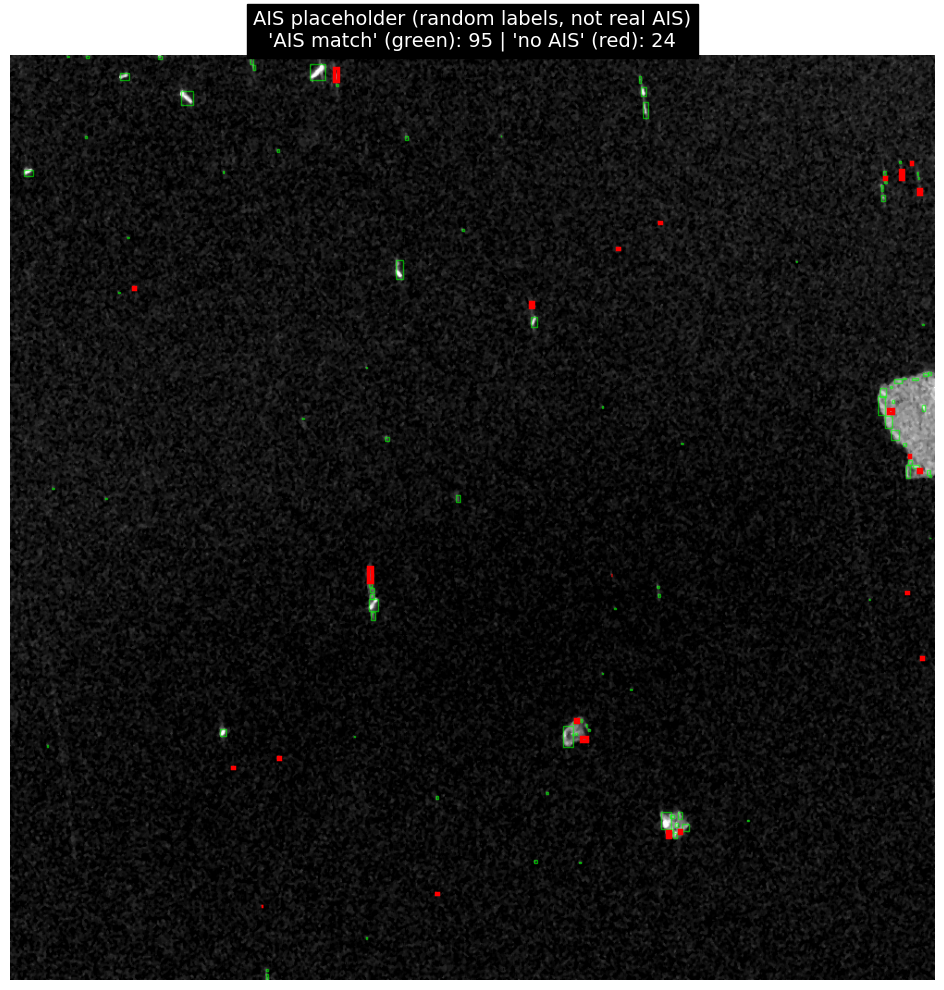

In [7]:
# --- STAGE 5: AIS PLACEHOLDER (RANDOM LABELS, NO AIS DATA) ---
import random
import matplotlib.patches as patches
import matplotlib.pyplot as plt

print("--- AIS PLACEHOLDER ---")
print("No AIS data is used. Each detection gets a random label (80% 'AIS match', 20% 'no AIS').")

random.seed(42)  # fixed seed so the placeholder output is the same on every run

def simulate_ais_api_call():
    """Placeholder for a real AIS lookup: returns a random label (80% True, 20% False)."""
    return random.choices([True, False], weights=[0.8, 0.2])[0]

legal_vessels = []
dark_vessels = []

for kutu in valid_vessels:
    if simulate_ais_api_call():
        legal_vessels.append(kutu)
    else:
        dark_vessels.append(kutu)

print(f"\nDetections:                {len(valid_vessels)}")
print(f"Random label 'AIS match':  {len(legal_vessels)}")
print(f"Random label 'no AIS':     {len(dark_vessels)}")
print("These labels are random and carry no information.\n")

fig, ax = plt.subplots(1, 1, figsize=(14, 10))
ax.imshow(vh_temiz, cmap='gray', vmin=-25, vmax=-5)

for kutu in legal_vessels:
    y_start, y_stop = kutu[0].start, kutu[0].stop
    x_start, x_stop = kutu[1].start, kutu[1].stop
    rect = patches.Rectangle((x_start, y_start), x_stop - x_start, y_stop - y_start,
                             linewidth=1, edgecolor='lime', facecolor='none', alpha=0.6)
    ax.add_patch(rect)

for kutu in dark_vessels:
    y_start, y_stop = kutu[0].start, kutu[0].stop
    x_start, x_stop = kutu[1].start, kutu[1].stop
    rect = patches.Rectangle((x_start, y_start), x_stop - x_start, y_stop - y_start,
                             linewidth=2.5, edgecolor='red', facecolor='none')
    ax.add_patch(rect)

ax.set_title(f"AIS placeholder (random labels, not real AIS)\n'AIS match' (green): {len(legal_vessels)} | 'no AIS' (red): {len(dark_vessels)}",
             color='white', backgroundcolor='black', fontsize=14)
ax.axis('off')

plt.tight_layout()
plt.show()
